# Section 4: Deep Neural Networks

**Student:** Wu Shangxuan  
**GitHub username:** WuShangxuan0106  
**Primary task:** Regression

This notebook completes the Section 4 assignment on the fixed OpenPoly prediction task. The experiment keeps the Section 3 target definition and test split, derives validation rows only from the old training portion, and evaluates the final MLP and CNN once after all choices are locked.

## 0. Setup and reproducibility

The notebook runs on CPU. A seed reduces variation on this software/hardware setup, but it does not guarantee identical results across every platform or backend.

In [1]:
%matplotlib inline

from pathlib import Path
import hashlib
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

DEVICE = torch.device("cpu")
print({
    "device": str(DEVICE),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "torch": torch.__version__,
    "seed": SEED,
})

{'device': 'cpu', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit_learn': '1.9.0', 'torch': '2.13.0', 'seed': 42}


## 1. Experiment contract

| Decision | Your choice | Why it is correct |
|---|---|---|
| Primary task and target | Regression; target `HOMO_LUMO_Gap_eV` in eV | The target is continuous, and this reuses the Section 3 regression baseline. |
| Train/validation/test row IDs | 592 train, 148 validation, 186 test rows; identifiers are values from the original `id` column | The test rows match Section 3. Validation is derived from the old training rows only, so the test set stays closed. |
| Section 3 baseline and saved result | `StandardScaler + LinearRegression`; test R2 `0.2494`, RMSE `0.4519 eV` | This is the saved comparable baseline on the same target and test split. |
| MLP input columns | `Energy_Hatree`, `es`, `Isotropic_Polarizability_au`, `Inner_energy_correction_Hatree`, `Thermal_correction_to_Enthalpy_Hatree`, `Thermal_correction_to_Gibbs_Free_Energy_Hatree`, `Entropy_Hatree`, `Dipole_Debye`, `Gibbs_Free_Energy_Hatree`, `Enthalpy_Hatree` | These are the 10 honest calculated-property features from Section 3 after excluding identifiers, target-derived columns, and known target leaks. |
| CNN sequence column | `psmiles` | It is an ordered character sequence, so nearby positions have local meaning for a 1D convolution. |
| Model output shape | `(N, 1)`, unrestricted floating point | Single-target regression requires one continuous value per sample and no final activation. |
| Target shape and dtype | `(N, 1)`, `torch.float32` | The target must match the regression output shape for `MSELoss`. |
| Training loss | `MSELoss` | MSE matches a continuous target and directly penalizes squared error. |
| Probability/prediction conversion | Use the regression output directly | Regression does not use sigmoid, softmax, a class threshold, or argmax. |
| Primary model-selection metric | Validation RMSE, lower is better | RMSE keeps the target unit (eV). All checkpoints and controlled choices are selected on validation evidence only. |

**Leakage risks known before training:** `id` as a numeric predictor, the target itself, `HOMO_eV` and `LUMO_eV` because `HOMO_LUMO_Gap_eV = LUMO_eV - HOMO_eV`, preprocessing fitted outside the training rows, sequence vocabulary or maximum length learned from validation/test data, and any model choice made after inspecting test scores.

**Rule for opening the test set:** Keep the 186 test rows unused while choosing preprocessing, vocabulary, architectures, learning rates, epoch counts, and checkpoints. After those choices are locked, restore the selected MLP and CNN checkpoints and evaluate the untouched test set exactly once.

The fixed split is reproduced as follows: filter `Energy_Hatree == 0`, use `train_test_split(np.arange(926), test_size=0.2, random_state=42)` for the original Section 3 train/test boundary, then use `train_test_split(old_train_indices, test_size=0.2, random_state=42)` for train/validation.

## 2. Manual forward pass and backpropagation

For the one-sample network:

\[
z_1 = W_1x+b_1=[1.0,1.0], \quad h=\operatorname{ReLU}(z_1)=[1.0,1.0]
\]

\[
\text{logit}=W_2h+b_2=0.8(1)-0.4(1)+0.1=0.5
\]

\[
p=\sigma(0.5)=0.6224593312, \quad L=-\log(p)=0.4740769842
\]

The backward pass starts with

\[
\frac{\partial L}{\partial\text{logit}}=p-y=-0.3775406688.
\]

Then

\[
\frac{\partial L}{\partial W_2}=[-0.3775406688,-0.3775406688], \quad
\frac{\partial L}{\partial b_2}=-0.3775406688.
\]

\[
\frac{\partial L}{\partial h}=[0.8(-0.3775406688),-0.4(-0.3775406688)]
=[-0.3020325350,0.1510162674]
\]

Both ReLU derivatives are 1, so `dL/dz1` is unchanged. Therefore

\[
\frac{\partial L}{\partial W_1}=
\begin{bmatrix}
-0.3020325350 & -0.6040650700\\
0.1510162674 & 0.3020325350
\end{bmatrix},
\quad
\frac{\partial L}{\partial b_1}=[-0.3020325350,0.1510162674].
\]

After a learning-rate `0.1` update, the updated loss is about `0.3717513814`, so the loss decreases as expected.

In [ ]:
# Manual forward, backward, and one gradient-descent update in float64.
x_manual = torch.tensor([1.0, 2.0], dtype=torch.float64)
y_manual = torch.tensor(1.0, dtype=torch.float64)

W1_manual = torch.tensor([[0.5, 0.25], [-0.5, 1.0]], dtype=torch.float64)
b1_manual = torch.tensor([0.0, -0.5], dtype=torch.float64)
W2_manual = torch.tensor([0.8, -0.4], dtype=torch.float64)
b2_manual = torch.tensor(0.1, dtype=torch.float64)

z1_manual = W1_manual @ x_manual + b1_manual
h_manual = torch.relu(z1_manual)
logit_manual = W2_manual @ h_manual + b2_manual
prob_manual = torch.sigmoid(logit_manual)
loss_manual = torch.nn.functional.binary_cross_entropy_with_logits(logit_manual, y_manual)

dlogit = prob_manual - y_manual
dW2 = dlogit * h_manual
db2 = dlogit
dh = W2_manual * dlogit
dz1 = dh.clone()  # Both ReLU inputs are positive.
dW1 = torch.outer(dz1, x_manual)
db1 = dz1

lr_manual = 0.1
with torch.no_grad():
    W1_updated = W1_manual - lr_manual * dW1
    b1_updated = b1_manual - lr_manual * db1
    W2_updated = W2_manual - lr_manual * dW2
    b2_updated = b2_manual - lr_manual * db2

z1_updated = W1_updated @ x_manual + b1_updated
h_updated = torch.relu(z1_updated)
logit_updated = W2_updated @ h_updated + b2_updated
prob_updated = torch.sigmoid(logit_updated)
loss_updated = torch.nn.functional.binary_cross_entropy_with_logits(logit_updated, y_manual)

print("Forward values")
print("z1:", z1_manual.numpy())
print("h:", h_manual.numpy())
print("logit:", float(logit_manual))
print("probability:", float(prob_manual))
print("loss:", float(loss_manual))

print("\nManual gradients")
print("dL/dW1:", dW1.numpy())
print("dL/db1:", db1.numpy())
print("dL/dW2:", dW2.numpy())
print("dL/db2:", float(db2))

print("\nUpdated parameters")
print("W1:", W1_updated.numpy())
print("b1:", b1_updated.numpy())
print("W2:", W2_updated.numpy())
print("b2:", float(b2_updated))
print("updated logit:", float(logit_updated))
print("updated probability:", float(prob_updated))
print("updated loss:", float(loss_updated))
print("loss decrease:", float(loss_manual - loss_updated))

Forward values
z1: [1. 1.]
h: [1. 1.]
logit: 0.5
probability: 0.6224593312018546
loss: 0.4740769841801067

Manual gradients
dL/dW1: [[-0.30203254 -0.60406507]
 [ 0.15101627  0.30203254]]
dL/db1: [-0.30203254  0.15101627]
dL/dW2: [-0.37754067 -0.37754067]
dL/db2: -0.3775406687981454

Updated parameters
W1: [[ 0.53020325  0.31040651]
 [-0.51510163  0.96979675]]
b1: [ 0.03020325 -0.51510163]
W2: [ 0.83775407 -0.36224593]
b2: 0.13775406687981456
updated logit: 0.7979026086208707
updated probability: 0.6895256501016556
updated loss: 0.3717513814230916
loss decrease: 0.10232560275701508


### 2.1 Verify the trace with autograd

The manual gradients are compared with PyTorch Autograd using the same `float64` tensors.

In [ ]:
# Autograd verification of the manual trace.
torch.manual_seed(SEED)
x_ag = torch.tensor([1.0, 2.0], dtype=torch.float64)
y_ag = torch.tensor(1.0, dtype=torch.float64)
W1_ag = torch.tensor([[0.5, 0.25], [-0.5, 1.0]], dtype=torch.float64, requires_grad=True)
b1_ag = torch.tensor([0.0, -0.5], dtype=torch.float64, requires_grad=True)
W2_ag = torch.tensor([0.8, -0.4], dtype=torch.float64, requires_grad=True)
b2_ag = torch.tensor(0.1, dtype=torch.float64, requires_grad=True)

logit_ag = W2_ag @ torch.relu(W1_ag @ x_ag + b1_ag) + b2_ag
loss_ag = torch.nn.functional.binary_cross_entropy_with_logits(logit_ag, y_ag)
loss_ag.backward()

manual_grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
autograd_grads = {"W1": W1_ag.grad, "b1": b1_ag.grad, "W2": W2_ag.grad, "b2": b2_ag.grad}

max_abs_diff = 0.0
for name in manual_grads:
    diff = torch.max(torch.abs(manual_grads[name] - autograd_grads[name])).item()
    max_abs_diff = max(max_abs_diff, diff)
    print(f"{name}: manual={manual_grads[name].numpy()}, autograd={autograd_grads[name].numpy()}, max_abs_diff={diff:.3e}")
print(f"Maximum absolute difference across all parameters: {max_abs_diff:.3e}")

W1: manual=[[-0.30203254 -0.60406507]
 [ 0.15101627  0.30203254]], autograd=[[-0.30203254 -0.60406507]
 [ 0.15101627  0.30203254]], max_abs_diff=0.000e+00
b1: manual=[-0.30203254  0.15101627], autograd=[-0.30203254  0.15101627], max_abs_diff=0.000e+00
W2: manual=[-0.37754067 -0.37754067], autograd=[-0.37754067 -0.37754067], max_abs_diff=0.000e+00
b2: manual=-0.3775406687981454, autograd=-0.3775406687981454, max_abs_diff=0.000e+00
Maximum absolute difference across all parameters: 0.000e+00


### 2.2 Sigmoid and ReLU gradients

Sigmoid saturates at both ends, so its derivative approaches zero for large-magnitude inputs. ReLU has derivative 1 on the positive side and 0 on the negative side, which avoids positive-side saturation but can produce an inactive unit if its input stays negative.

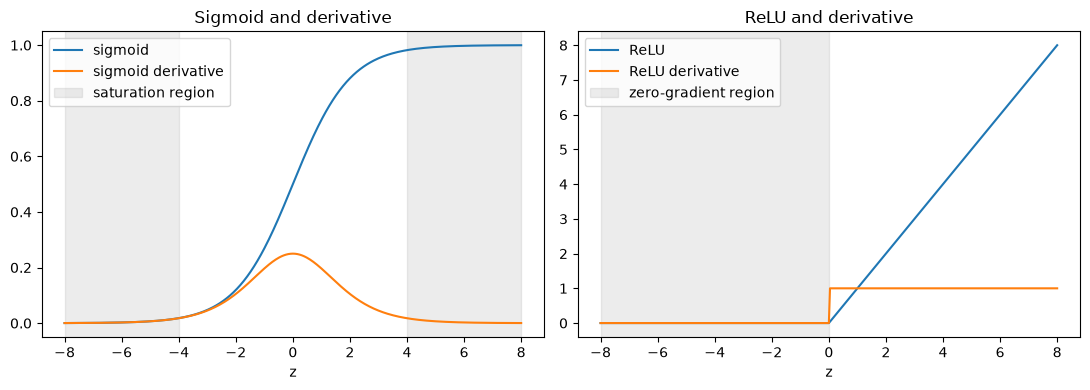

In [ ]:
z = np.linspace(-8, 8, 401)
sigmoid = 1.0 / (1.0 + np.exp(-z))
sigmoid_grad = sigmoid * (1.0 - sigmoid)
relu = np.maximum(0.0, z)
relu_grad = (z > 0).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z, sigmoid, label="sigmoid")
axes[0].plot(z, sigmoid_grad, label="sigmoid derivative")
axes[0].axvspan(-8, -4, color="gray", alpha=0.15, label="saturation region")
axes[0].axvspan(4, 8, color="gray", alpha=0.15)
axes[0].set_title("Sigmoid and derivative")
axes[0].set_xlabel("z")
axes[0].legend()

axes[1].plot(z, relu, label="ReLU")
axes[1].plot(z, relu_grad, label="ReLU derivative")
axes[1].axvspan(-8, 0, color="gray", alpha=0.15, label="zero-gradient region")
axes[1].set_title("ReLU and derivative")
axes[1].set_xlabel("z")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Output-target-loss contract checks

The three toy examples below verify that the output shape, target shape, target dtype, scalar loss, probabilities, and predictions agree with the intended statistical task.

In [5]:
# Regression contract check.
pred_reg = torch.tensor([[0.2], [0.7], [-0.1], [1.3]], dtype=torch.float32)
target_reg = torch.tensor([[0.0], [1.0], [0.3], [1.0]], dtype=torch.float32)
loss_reg = nn.MSELoss()(pred_reg, target_reg)
print("Regression")
print("output shape:", tuple(pred_reg.shape), "target shape:", tuple(target_reg.shape), "target dtype:", target_reg.dtype)
print("scalar loss:", float(loss_reg), "loss shape:", tuple(loss_reg.shape))
print("predictions:", pred_reg.squeeze(1).numpy())

Regression
output shape: (4, 1) target shape: (4, 1) target dtype: torch.float32
scalar loss: 0.0949999988079071 loss shape: ()
predictions: [ 0.2  0.7 -0.1  1.3]


In [6]:
# Binary classification contract check.
logits_bin = torch.tensor([[0.4], [-1.2], [2.0], [-0.3]], dtype=torch.float32)
target_bin = torch.tensor([[1.0], [0.0], [1.0], [0.0]], dtype=torch.float32)
loss_bin = nn.BCEWithLogitsLoss()(logits_bin, target_bin)
prob_bin = torch.sigmoid(logits_bin)
pred_bin = (prob_bin >= 0.5).float()
print("Binary classification")
print("logit shape:", tuple(logits_bin.shape), "target shape:", tuple(target_bin.shape), "target dtype:", target_bin.dtype)
print("scalar loss:", float(loss_bin))
print("probabilities:", prob_bin.squeeze(1).numpy())
print("predictions:", pred_bin.squeeze(1).numpy())

Binary classification
logit shape: (4, 1) target shape: (4, 1) target dtype: torch.float32
scalar loss: 0.36439523100852966
probabilities: [0.59868765 0.23147522 0.880797   0.4255575 ]
predictions: [1. 0. 1. 0.]


In [7]:
# Multiclass classification contract check.
logits_multi = torch.tensor([[1.0, 0.0, -1.0], [0.1, 0.8, 0.4], [2.0, -0.5, 0.2]], dtype=torch.float32)
target_multi = torch.tensor([0, 2, 0], dtype=torch.long)
loss_multi = nn.CrossEntropyLoss()(logits_multi, target_multi)
prob_multi = torch.softmax(logits_multi, dim=1)
pred_multi = torch.argmax(logits_multi, dim=1)
print("Multiclass classification")
print("logit shape:", tuple(logits_multi.shape), "target shape:", tuple(target_multi.shape), "target dtype:", target_multi.dtype)
print("scalar loss:", float(loss_multi))
print("softmax row sums:", prob_multi.sum(dim=1).numpy())
print("predicted class indices:", pred_multi.numpy())

Multiclass classification
logit shape: (3, 3) target shape: (3,) target dtype: torch.int64
scalar loss: 0.6006515026092529
softmax row sums: [1.         1.         0.99999994]
predicted class indices: [0 1 0]


**Why are class indices usually preferable to one-hot targets for ordinary multiclass `CrossEntropyLoss`?** Class indices are the native interface for hard mutually exclusive labels: the model returns `(N, C)` logits and the target is `(N,)` with `torch.long` values. One-hot encoding is unnecessary and can obscure mistakes with shape or dtype.

**How would the output, target, loss, and probability conversion change for multi-label classification?** The output would remain `(N, C)` logits, but the target would be an `(N, C)` floating multi-hot vector because several labels can be true. The loss would be `BCEWithLogitsLoss`, and each label would receive an independent sigmoid probability.

**Why should sigmoid or softmax not appear before the classification losses above?** `BCEWithLogitsLoss` and `CrossEntropyLoss` already combine the probability transformation with the loss in a numerically stable way. Applying sigmoid or softmax first would transform the values twice and reduce stability.

## 4. Load the fixed data split

The CSV is loaded with repository-relative paths. The target definition and the original Section 3 test boundary are preserved; validation is derived only from the old training portion.

In [8]:
REPOSITORY_ROOT = Path.cwd()
while not (REPOSITORY_ROOT / "sections").exists() and REPOSITORY_ROOT.parent != REPOSITORY_ROOT:
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent

DATA_PATH = REPOSITORY_ROOT / "sections/s02/homework/openpoly_calculated_properties.csv"
df = pd.read_csv(DATA_PATH)

TARGET_COL = "HOMO_LUMO_Gap_eV"
SEQUENCE_COL = "psmiles"
MLP_FEATURES = [
    "Energy_Hatree",
    "es",
    "Isotropic_Polarizability_au",
    "Inner_energy_correction_Hatree",
    "Thermal_correction_to_Enthalpy_Hatree",
    "Thermal_correction_to_Gibbs_Free_Energy_Hatree",
    "Entropy_Hatree",
    "Dipole_Debye",
    "Gibbs_Free_Energy_Hatree",
    "Enthalpy_Hatree",
]

model_df = df[df["Energy_Hatree"] != 0].copy().reset_index(drop=True)
old_train_idx, test_idx = train_test_split(
    np.arange(len(model_df)),
    test_size=0.2,
    random_state=SEED,
)
train_idx, val_idx = train_test_split(
    old_train_idx,
    test_size=0.2,
    random_state=SEED,
)

train_df = model_df.loc[train_idx].copy()
val_df = model_df.loc[val_idx].copy()
test_df = model_df.loc[test_idx].copy()

split_ids = {
    "train": train_df["id"].to_numpy(),
    "validation": val_df["id"].to_numpy(),
    "test": test_df["id"].to_numpy(),
}

print("Repository root:", REPOSITORY_ROOT)
print("Raw rows:", len(df), "valid rows:", len(model_df))
print("Split sizes:", {name: len(ids) for name, ids in split_ids.items()})
for name, ids in split_ids.items():
    digest = hashlib.sha256(",".join(map(str, ids)).encode()).hexdigest()
    print(f"{name} id sha256: {digest}")

Repository root: /Users/wushangxuan/2026-summar-ai
Raw rows: 1000 valid rows: 926
Split sizes: {'train': 592, 'validation': 148, 'test': 186}
train id sha256: c89a15cad4591bb986051a43b39423c2128dcda7a0b404a9299649747a762e8f
validation id sha256: 8ec28e7221e2e3919de57fe85f9c05c2880d67da0d7d74269dcbe5ec6d9fe8ec
test id sha256: f491c55dbfc26c738dd015d236ad3496917fe226089eae12d7316ba2375d54ff


In [9]:
# Prove identifiers are unique within each split and disjoint across splits.
train_id_set = set(split_ids["train"])
val_id_set = set(split_ids["validation"])
test_id_set = set(split_ids["test"])

assert len(train_id_set) == len(split_ids["train"])
assert len(val_id_set) == len(split_ids["validation"])
assert len(test_id_set) == len(split_ids["test"])
assert train_id_set.isdisjoint(val_id_set)
assert train_id_set.isdisjoint(test_id_set)
assert val_id_set.isdisjoint(test_id_set)

print("Unique IDs within each split: True")
print("Train ∩ validation:", train_id_set & val_id_set)
print("Train ∩ test:", train_id_set & test_id_set)
print("Validation ∩ test:", val_id_set & test_id_set)

Unique IDs within each split: True
Train ∩ validation: set()
Train ∩ test: set()
Validation ∩ test: set()


## 5. Audit the exact model inputs

### 5.1 Tabular inputs for the MLP

The audit below checks the target distribution, missing values, descriptive statistics, and target correlations. The known leakage columns `HOMO_eV`, `LUMO_eV`, `id`, and the target itself are excluded from the MLP inputs.

,train,validation,test
count,592.0000,148.0000,186.0000
mean,8.3040,8.3203,8.3116
std,0.4654,0.4927,0.5230
min,6.5123,6.8784,4.4689
25%,8.0154,7.9904,8.0888
50%,8.3151,8.3470,8.3641
75%,8.5936,8.5938,8.6386
max,9.8756,10.0010,9.6941


,train_missing,validation_missing,test_missing
Energy_Hatree,0,0,0
es,0,0,0
Isotropic_Polarizability_au,0,0,0
Inner_energy_correction_Hatree,0,0,0
Thermal_correction_to_Enthalpy_Hatree,0,0,0
Thermal_correction_to_Gibbs_Free_Energy_Hatree,0,0,0
Entropy_Hatree,0,0,0
Dipole_Debye,0,0,0
Gibbs_Free_Energy_Hatree,0,0,0
Enthalpy_Hatree,0,0,0


,pearson,spearman
Isotropic_Polarizability_au,-0.2254,-0.1997
es,-0.1343,-0.1381
Thermal_correction_to_Gibbs_Free_Energy_Hatree,0.0862,0.0918
Entropy_Hatree,0.0455,0.0713
Dipole_Debye,-0.0438,-0.0312
Inner_energy_correction_Hatree,-0.0219,0.0606
Gibbs_Free_Energy_Hatree,0.0159,0.0006
Energy_Hatree,0.0158,0.0006
Enthalpy_Hatree,0.0158,0.0006
Thermal_correction_to_Enthalpy_Hatree,NaN,NaN


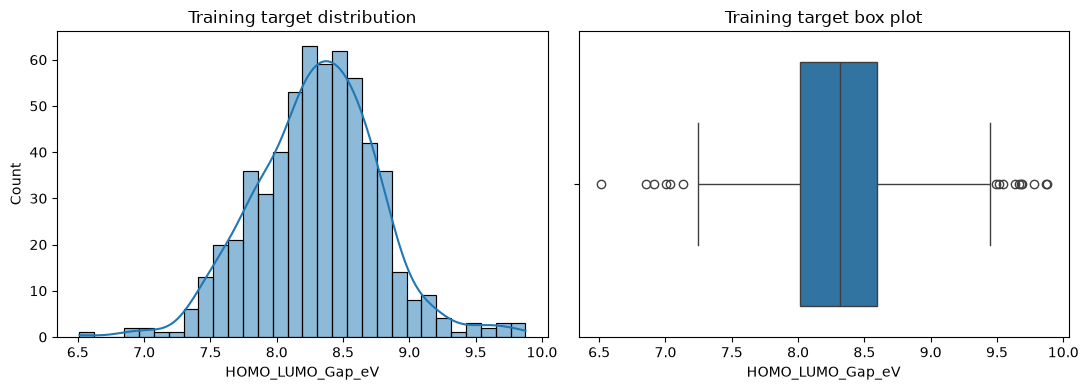

In [10]:
target_summary = pd.DataFrame({
    "train": train_df[TARGET_COL].describe(),
    "validation": val_df[TARGET_COL].describe(),
    "test": test_df[TARGET_COL].describe(),
})
display(target_summary.round(4))

missing_table = pd.DataFrame({
    "train_missing": train_df[MLP_FEATURES].isna().sum(),
    "validation_missing": val_df[MLP_FEATURES].isna().sum(),
    "test_missing": test_df[MLP_FEATURES].isna().sum(),
})
display(missing_table)

corr_table = pd.DataFrame({
    "pearson": train_df[MLP_FEATURES + [TARGET_COL]].corr()[TARGET_COL].drop(TARGET_COL),
    "spearman": train_df[MLP_FEATURES + [TARGET_COL]].corr(method="spearman")[TARGET_COL].drop(TARGET_COL),
}).sort_values("pearson", key=lambda s: s.abs(), ascending=False)
display(corr_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(train_df[TARGET_COL], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Training target distribution")
sns.boxplot(x=train_df[TARGET_COL], ax=axes[1])
axes[1].set_title("Training target box plot")
plt.tight_layout()
plt.show()

Transformed tabular shapes: torch.Size([592, 10]) torch.Size([148, 10]) torch.Size([186, 10])
Scaled training means: [ 0. -0.  0. -0. -0.  0.  0. -0.  0. -0.]
Scaled training stds: [1. 1. 1. 1. 0. 1. 1. 1. 1. 1.]


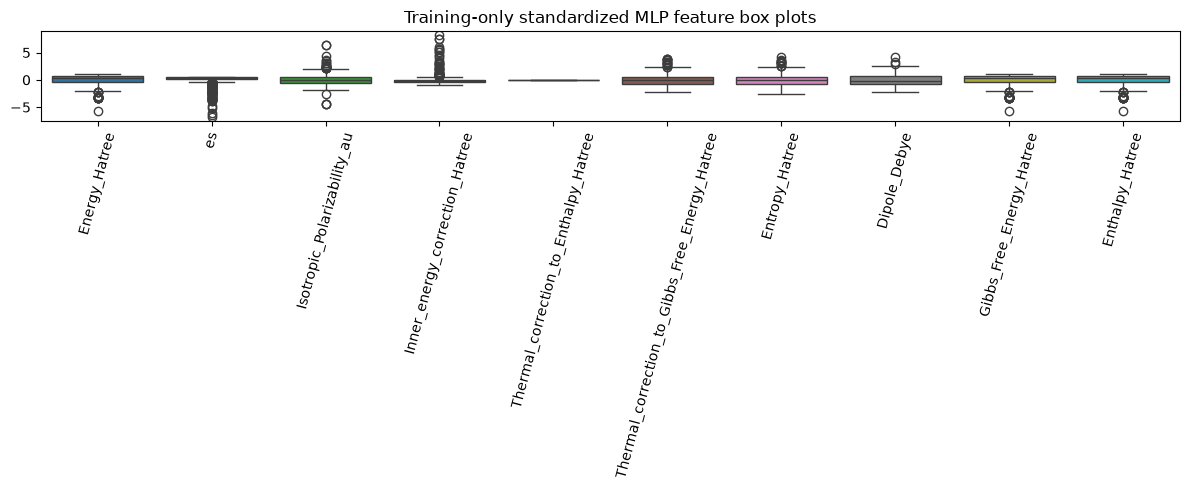

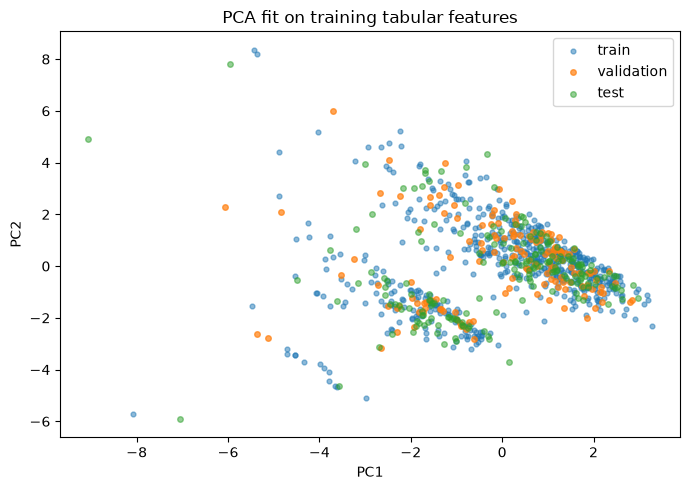

In [11]:
# Fit numerical preprocessing on training data only and verify scaling properties.
scaler = StandardScaler().fit(train_df[MLP_FEATURES])

X_train = scaler.transform(train_df[MLP_FEATURES]).astype(np.float32)
X_val = scaler.transform(val_df[MLP_FEATURES]).astype(np.float32)
X_test = scaler.transform(test_df[MLP_FEATURES]).astype(np.float32)

y_train = train_df[TARGET_COL].to_numpy(dtype=np.float32).reshape(-1, 1)
y_val = val_df[TARGET_COL].to_numpy(dtype=np.float32).reshape(-1, 1)
y_test = test_df[TARGET_COL].to_numpy(dtype=np.float32).reshape(-1, 1)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

print("Transformed tabular shapes:", X_train_t.shape, X_val_t.shape, X_test_t.shape)
print("Scaled training means:", np.round(X_train.mean(axis=0), 6))
print("Scaled training stds:", np.round(X_train.std(axis=0), 6))

scaler_plot = StandardScaler().fit(X_train)
scaled_train_for_plot = scaler_plot.transform(X_train)
plt.figure(figsize=(12, 5))
sns.boxplot(data=pd.DataFrame(scaled_train_for_plot, columns=MLP_FEATURES))
plt.xticks(rotation=75)
plt.title("Training-only standardized MLP feature box plots")
plt.tight_layout()
plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(X_train)
pca_train = pca.transform(X_train)
pca_val = pca.transform(X_val)
pca_test = pca.transform(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(pca_train[:, 0], pca_train[:, 1], s=12, alpha=0.5, label="train")
plt.scatter(pca_val[:, 0], pca_val[:, 1], s=16, alpha=0.7, label="validation")
plt.scatter(pca_test[:, 0], pca_test[:, 1], s=16, alpha=0.5, label="test")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA fit on training tabular features")
plt.legend()
plt.tight_layout()
plt.show()

### 5.2 Sequence inputs for the CNN

The character vocabulary and maximum sequence length are learned from the training split only. Padding and unknown tokens are explicit, and `psmiles` is kept in its original order because local character patterns are meaningful for `Conv1d`.

,train,validation,test
count,592.00,148.00,186.00
mean,53.44,54.55,52.81
std,9.13,8.42,9.81
min,35.00,37.00,38.00
50%,52.00,54.00,50.00
75%,58.00,60.00,56.00
90%,65.90,65.30,65.50
95%,72.45,68.65,74.75
99%,79.00,80.06,89.90
max,98.00,81.00,97.00


Training character count: 31639
Top 15 training characters:


c    6688
(    4460
)    4460
C    4184
O    2995
=    2237
N    1557
1    1530
*    1184
2     760
F     299
S     230
n     218
3     164
B     155
Name: count, dtype: int64

Training-only 95th-percentile maximum length: 72


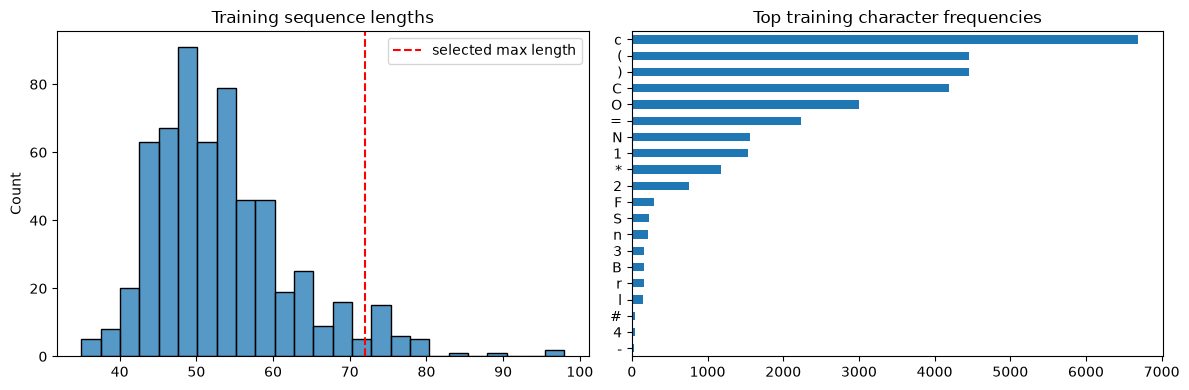

In [12]:
train_sequences = train_df[SEQUENCE_COL].astype(str).tolist()
val_sequences = val_df[SEQUENCE_COL].astype(str).tolist()
test_sequences = test_df[SEQUENCE_COL].astype(str).tolist()

length_summary = pd.DataFrame({
    "train": pd.Series([len(s) for s in train_sequences]).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]),
    "validation": pd.Series([len(s) for s in val_sequences]).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]),
    "test": pd.Series([len(s) for s in test_sequences]).describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]),
})
display(length_summary.round(2))

train_char_counts = pd.Series(list("".join(train_sequences))).value_counts()
print("Training character count:", int(train_char_counts.sum()))
print("Top 15 training characters:")
display(train_char_counts.head(15))

MAX_LEN = int(np.percentile([len(s) for s in train_sequences], 95))
print("Training-only 95th-percentile maximum length:", MAX_LEN)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot([len(s) for s in train_sequences], bins=25, ax=axes[0])
axes[0].axvline(MAX_LEN, color="red", linestyle="--", label="selected max length")
axes[0].set_title("Training sequence lengths")
axes[0].legend()
train_char_counts.head(20).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top training character frequencies")
plt.tight_layout()
plt.show()

In [13]:
# Build the training-only vocabulary, then encode, pad, and truncate all splits.
PAD_TOKEN = "<pad>"
UNK_TOKEN = "<unk>"
PAD_INDEX = 0
UNK_INDEX = 1

train_vocab_chars = sorted(set("".join(train_sequences)))
index_to_token = [PAD_TOKEN, UNK_TOKEN] + train_vocab_chars
token_to_index = {token: idx for idx, token in enumerate(index_to_token)}
VOCAB_SIZE = len(index_to_token)

def encode_sequences(sequences):
    indices = np.full((len(sequences), MAX_LEN), PAD_INDEX, dtype=np.int64)
    unknown_count = 0
    truncated_count = 0
    for row, sequence in enumerate(sequences):
        if len(sequence) > MAX_LEN:
            truncated_count += 1
        for col, char in enumerate(sequence[:MAX_LEN]):
            if char in token_to_index and token_to_index[char] >= 2:
                indices[row, col] = token_to_index[char]
            else:
                indices[row, col] = UNK_INDEX
                unknown_count += 1
    tensor_indices = torch.tensor(indices, dtype=torch.long)
    one_hot = torch.nn.functional.one_hot(tensor_indices, num_classes=VOCAB_SIZE).float().permute(0, 2, 1).contiguous()
    padding_rate = float((tensor_indices == PAD_INDEX).float().mean().item())
    return tensor_indices, one_hot, unknown_count, truncated_count, padding_rate

seq_train_idx, X_seq_train, unk_train, trunc_train, pad_train = encode_sequences(train_sequences)
seq_val_idx, X_seq_val, unk_val, trunc_val, pad_val = encode_sequences(val_sequences)
seq_test_idx, X_seq_test, unk_test, trunc_test, pad_test = encode_sequences(test_sequences)

sequence_report = pd.DataFrame({
    "vocab_size": [VOCAB_SIZE] * 3,
    "unknown_tokens": [unk_train, unk_val, unk_test],
    "truncated_sequences": [trunc_train, trunc_val, trunc_test],
    "padding_rate": [pad_train, pad_val, pad_test],
    "encoded_shape": [str(tuple(X_seq_train.shape)), str(tuple(X_seq_val.shape)), str(tuple(X_seq_test.shape))],
}, index=["train", "validation", "test"])
display(sequence_report)

X_seq_train_t = X_seq_train
X_seq_val_t = X_seq_val
X_seq_test_t = X_seq_test
print("CNN input shape train/validation/test:", X_seq_train_t.shape, X_seq_val_t.shape, X_seq_test_t.shape)

,vocab_size,unknown_tokens,truncated_sequences,padding_rate,encoded_shape
train,30,0,30,0.261871,"(592, 30, 72)"
validation,30,0,4,0.244932,"(148, 30, 72)"
test,30,1,11,0.274791,"(186, 30, 72)"


CNN input shape train/validation/test: torch.Size([592, 30, 72]) torch.Size([148, 30, 72]) torch.Size([186, 30, 72])


**Why does the sequence representation have meaningful local order?** Adjacent characters in `psmiles` encode local substructure and syntax patterns. A convolution kernel can slid over nearby characters and learn repeated local fragments.

**Why would an arbitrary ordering of tabular columns not justify the same convolutional assumption?** Reordering tabular columns does not create a scientific neighborhood relationship. A CNN would treat arbitrary adjacent columns as neighbors, so the inductive bias would not match the data.

**What information can character tokenization, padding, or truncation distort?** Character tokenization may miss multi-character chemical tokens; padding introduces synthetic empty positions; truncation discards information from long sequences and can bias the model toward the retained prefix.

## 6. Shared training and evaluation utilities

The same helpers are used for MLP and CNN experiments. Validation never updates parameters, and every model restores the checkpoint with the best validation RMSE.

In [14]:
def make_loader(X, y, batch_size, shuffle):
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=shuffle)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    total_samples = 0
    for x_batch, y_batch in loader:
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x_batch)
        total_samples += len(x_batch)
    return total_loss / total_samples


@torch.no_grad()
def evaluate_regression(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    predictions = []
    targets = []
    for x_batch, y_batch in loader:
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        output = model(x_batch)
        loss = criterion(output, y_batch)
        total_loss += loss.item() * len(x_batch)
        total_samples += len(x_batch)
        predictions.append(output.cpu())
        targets.append(y_batch.cpu())
    predictions = torch.cat(predictions)
    targets = torch.cat(targets)
    mse = torch.mean((predictions - targets) ** 2).item()
    return {
        "loss": total_loss / total_samples,
        "mse": mse,
        "rmse": float(np.sqrt(mse)),
        "predictions": predictions.numpy().ravel(),
        "targets": targets.numpy().ravel(),
    }


def run_regression_training(model, train_loader, val_loader, epochs, learning_rate, weight_decay=0.0):
    torch.manual_seed(SEED)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    best_val_rmse = float("inf")
    best_state = None
    history = []
    start_time = time.perf_counter()
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_stats = evaluate_regression(model, val_loader, criterion)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_stats["loss"],
            "val_rmse": val_stats["rmse"],
        })
        if val_stats["rmse"] < best_val_rmse:
            best_val_rmse = val_stats["rmse"]
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    elapsed = time.perf_counter() - start_time
    model.load_state_dict(best_state)
    return pd.DataFrame(history), best_val_rmse, elapsed


def regression_metrics(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


def plot_history(history, title):
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], label="train loss")
    plt.plot(history["epoch"], history["val_loss"], label="validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 7. MLP experiment

The MLP uses standardized tabular features and returns one unrestricted regression value per sample.

In [15]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, dropout=0.0):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(SEED)
mlp_shape_model = MLPRegressor(input_dim=X_train_t.shape[1], hidden_dim=64, dropout=0.0)
with torch.no_grad():
    sample_output = mlp_shape_model(X_train_t[:8])
print("MLP input shape:", tuple(X_train_t[:8].shape))
print("MLP output shape:", tuple(sample_output.shape))
print("MLP parameter count:", count_parameters(mlp_shape_model))
print(mlp_shape_model)

MLP input shape: (8, 10)
MLP output shape: (8, 1)
MLP parameter count: 769
MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


### 7.1 Controlled comparison plan

| Run | Single main change | Prediction before training | Optimizer | Learning rate | Batch size | Regularization | Max epochs / stopping |
|---|---|---|---|---:|---:|---|---|
| MLP-A | Baseline learning rate | Should optimize more slowly and reach a higher validation RMSE. | Adam | 0.001 | 32 | None | 80 epochs; best validation RMSE |
| MLP-B | Learning rate changed from 0.001 to 0.01 | Should reduce validation RMSE faster if optimization was the limiting factor. | Adam | 0.01 | 32 | None | 80 epochs; best validation RMSE |

In [16]:
mlp_train_loader = make_loader(X_train_t, y_train_t, batch_size=32, shuffle=True)
mlp_val_loader = make_loader(X_val_t, y_val_t, batch_size=64, shuffle=False)
mlp_test_loader = make_loader(X_test_t, y_test_t, batch_size=64, shuffle=False)

torch.manual_seed(SEED)
mlp_a = MLPRegressor(input_dim=X_train_t.shape[1], hidden_dim=64, dropout=0.0)
mlp_history_a, mlp_best_val_a, mlp_time_a = run_regression_training(
    mlp_a, mlp_train_loader, mlp_val_loader, epochs=80, learning_rate=0.001
)

torch.manual_seed(SEED)
mlp_b = MLPRegressor(input_dim=X_train_t.shape[1], hidden_dim=64, dropout=0.0)
mlp_history_b, mlp_best_val_b, mlp_time_b = run_regression_training(
    mlp_b, mlp_train_loader, mlp_val_loader, epochs=80, learning_rate=0.01
)

mlp_results = pd.DataFrame({
    "best_val_rmse": [mlp_best_val_a, mlp_best_val_b],
    "training_seconds": [mlp_time_a, mlp_time_b],
}, index=["MLP-A", "MLP-B"])
display(mlp_results.round(4))

if mlp_best_val_b <= mlp_best_val_a:
    selected_mlp_name = "MLP-B"
    selected_mlp = mlp_b
    selected_mlp_history = mlp_history_b
    selected_mlp_val_rmse = mlp_best_val_b
    selected_mlp_time = mlp_time_b
else:
    selected_mlp_name = "MLP-A"
    selected_mlp = mlp_a
    selected_mlp_history = mlp_history_a
    selected_mlp_val_rmse = mlp_best_val_a
    selected_mlp_time = mlp_time_a

print("Selected MLP:", selected_mlp_name, "validation RMSE:", round(selected_mlp_val_rmse, 4))

,best_val_rmse,training_seconds
MLP-A,0.6176,0.2458
MLP-B,0.4162,0.2452


Selected MLP: MLP-B validation RMSE: 0.4162


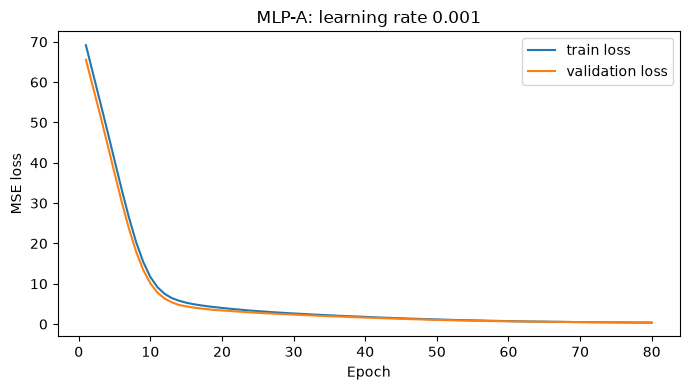

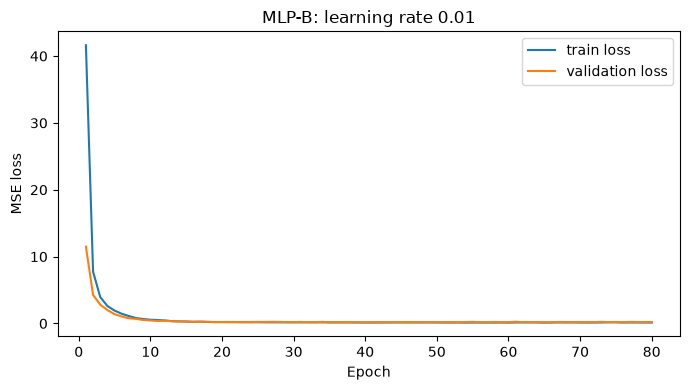

In [17]:
plot_history(mlp_history_a, "MLP-A: learning rate 0.001")
plot_history(mlp_history_b, "MLP-B: learning rate 0.01")

**Selected MLP and validation rule:** MLP-B was selected because it had the lower best validation RMSE. Both runs use a single hidden layer with width 64; the only controlled change is the learning rate.

**Did the controlled change behave as predicted?** Yes. Raising the learning rate from `0.001` to `0.01` improved validation RMSE substantially, which suggests that the lower learning rate was under-optimizing within 80 epochs.

**Evidence of underfitting, overfitting, unstable optimization, or no clear problem:** The MLP-A run remains more slowly optimized and has a worse validation result. MLP-B improves much faster and its training and validation losses stay reasonably close near the selected checkpoint, so there is no clear evidence of severe overfitting in the observed range.

**Alternative explanation or limitation:** The validation set is small and comes from the same random row split. A faster learning rate may help this split even if it is less stable under another seed.

## 8. 1D CNN experiment

The CNN uses character-level one-hot `psmiles` sequences with input shape `(N, vocabulary_size, sequence_length)`. It uses one `Conv1d`, ReLU, pooling, dropout, and a final regression layer.

In [18]:
class CharCNNRegressor(nn.Module):
    def __init__(self, vocab_size, channels=16, kernel_size=3, dropout=0.0):
        super().__init__()
        self.conv = nn.Conv1d(vocab_size, channels, kernel_size=kernel_size, padding=kernel_size // 2)
        self.activation = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(channels, 1)

    def forward(self, x):
        x = self.conv(x)
        x = self.activation(x)
        x = self.pool(x)
        x = x.flatten(start_dim=1)
        x = self.dropout(x)
        return self.head(x)

torch.manual_seed(SEED)
cnn_shape_model = CharCNNRegressor(vocab_size=VOCAB_SIZE, channels=16, kernel_size=3, dropout=0.0)
sample_batch = X_seq_train_t[:8]
with torch.no_grad():
    convolved = cnn_shape_model.conv(sample_batch)
    activated = cnn_shape_model.activation(convolved)
    pooled = cnn_shape_model.pool(activated)
    flattened = pooled.flatten(start_dim=1)
    output = cnn_shape_model.head(flattened)
print("Input shape:", tuple(sample_batch.shape))
print("After Conv1d:", tuple(convolved.shape))
print("After ReLU:", tuple(activated.shape))
print("After pooling:", tuple(pooled.shape))
print("After flatten:", tuple(flattened.shape))
print("Final output:", tuple(output.shape))
print("CNN parameter count:", count_parameters(cnn_shape_model))
print(cnn_shape_model)

Input shape: (8, 30, 72)
After Conv1d: (8, 16, 72)
After ReLU: (8, 16, 72)
After pooling: (8, 16, 1)
After flatten: (8, 16)
Final output: (8, 1)
CNN parameter count: 1473
CharCNNRegressor(
  (conv): Conv1d(30, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (activation): ReLU()
  (pool): AdaptiveMaxPool1d(output_size=1)
  (dropout): Dropout(p=0.0, inplace=False)
  (head): Linear(in_features=16, out_features=1, bias=True)
)


### 8.1 Controlled comparison plan

| Run | Single main change | Prediction before training | Optimizer | Learning rate | Batch size | Regularization | Max epochs / stopping |
|---|---|---|---|---:|---:|---|---|
| CNN-A | Kernel size 3 | Should learn short local character patterns. | Adam | 0.001 | 32 | None | 30 epochs; best validation RMSE |
| CNN-B | Kernel size changed from 3 to 5 | May capture slightly longer local patterns and improve validation RMSE. | Adam | 0.001 | 32 | None | 30 epochs; best validation RMSE |

In [19]:
cnn_train_loader = make_loader(X_seq_train_t, y_train_t, batch_size=32, shuffle=True)
cnn_val_loader = make_loader(X_seq_val_t, y_val_t, batch_size=64, shuffle=False)
cnn_test_loader = make_loader(X_seq_test_t, y_test_t, batch_size=64, shuffle=False)

torch.manual_seed(SEED)
cnn_a = CharCNNRegressor(vocab_size=VOCAB_SIZE, channels=16, kernel_size=3, dropout=0.0)
cnn_history_a, cnn_best_val_a, cnn_time_a = run_regression_training(
    cnn_a, cnn_train_loader, cnn_val_loader, epochs=30, learning_rate=0.001
)

torch.manual_seed(SEED)
cnn_b = CharCNNRegressor(vocab_size=VOCAB_SIZE, channels=16, kernel_size=5, dropout=0.0)
cnn_history_b, cnn_best_val_b, cnn_time_b = run_regression_training(
    cnn_b, cnn_train_loader, cnn_val_loader, epochs=30, learning_rate=0.001
)

cnn_results = pd.DataFrame({
    "best_val_rmse": [cnn_best_val_a, cnn_best_val_b],
    "training_seconds": [cnn_time_a, cnn_time_b],
}, index=["CNN-A", "CNN-B"])
display(cnn_results.round(4))

if cnn_best_val_b <= cnn_best_val_a:
    selected_cnn_name = "CNN-B"
    selected_cnn = cnn_b
    selected_cnn_history = cnn_history_b
    selected_cnn_val_rmse = cnn_best_val_b
    selected_cnn_time = cnn_time_b
else:
    selected_cnn_name = "CNN-A"
    selected_cnn = cnn_a
    selected_cnn_history = cnn_history_a
    selected_cnn_val_rmse = cnn_best_val_a
    selected_cnn_time = cnn_time_a

print("Selected CNN:", selected_cnn_name, "validation RMSE:", round(selected_cnn_val_rmse, 4))

,best_val_rmse,training_seconds
CNN-A,0.5449,0.9741
CNN-B,0.5216,1.3406


Selected CNN: CNN-B validation RMSE: 0.5216


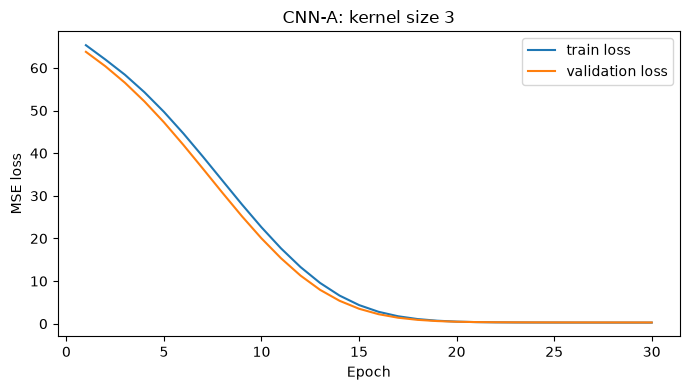

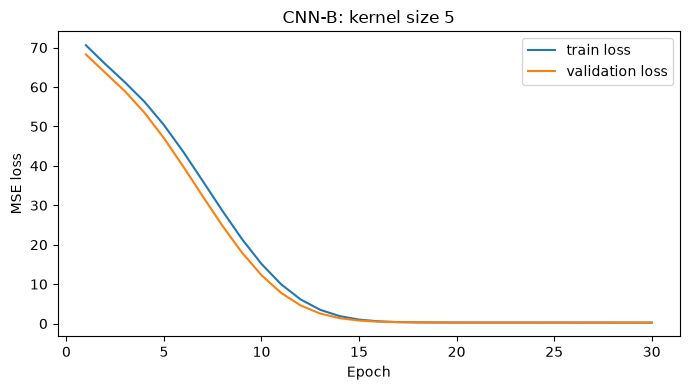

In [20]:
plot_history(cnn_history_a, "CNN-A: kernel size 3")
plot_history(cnn_history_b, "CNN-B: kernel size 5")

**Selected CNN and validation rule:** CNN-B was selected because it had the lower best validation RMSE. Both runs used the same channels, optimizer, learning rate, batch size, and epoch budget; only the kernel size changed.

**Did the controlled change behave as predicted?** Yes. Kernel size 5 slightly improved validation RMSE compared with kernel size 3, so slightly longer local character patterns helped on this split.

**What can one convolutional filter respond to in this input?** One filter can learn a weighted pattern over a short window of adjacent characters. The same filter slides across sequence positions, so it may detect repeated local motifs; this does not make the learned weights directly chemically interpretable.

**Evidence of underfitting, overfitting, unstable optimization, or no clear problem:** Training and validation loss both improve, and the selected validation checkpoint is near the end of training. The curves do not show severe overfitting, but CNN performance is still limited on test.

**Alternative explanation or limitation:** Character-level tokenization is only a rough representation of chemical structure. Padding and truncation also distort sequences, and a small neural network may not capture long-range dependencies.

## 9. Lock choices, evaluate the test set once, and compare

**Locked evaluation plan:** Use `MLP-B` with learning rate `0.01` and `CNN-B` with kernel size 5. Their checkpoints are the best-validation states saved during training. Regression uses raw model outputs, `MSELoss`, and the metrics R2, MAE, MSE, and RMSE. The test set is evaluated once below and is not used for any further model change.

Selected MLP: MLP-B
MLP test metrics: {'R2': 0.1945, 'MAE': 0.318, 'MSE': 0.2191, 'RMSE': 0.4681}
Selected CNN: CNN-B
CNN test metrics: {'R2': -0.1018, 'MAE': 0.3743, 'MSE': 0.2998, 'RMSE': 0.5475}


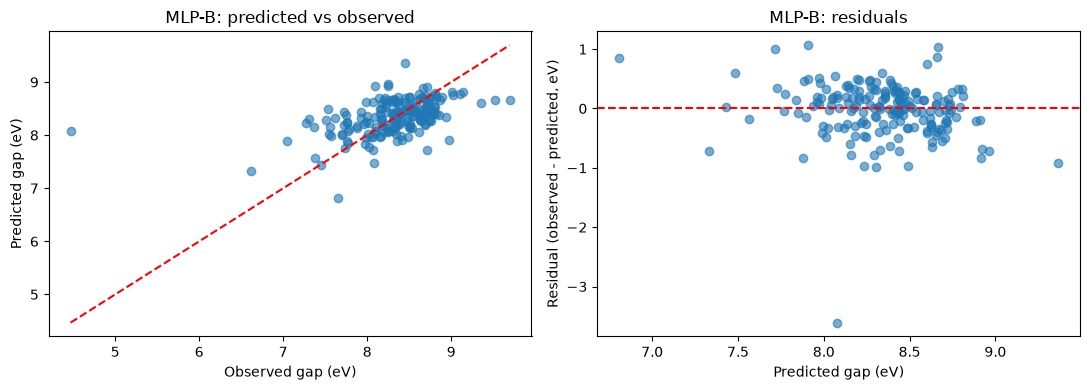

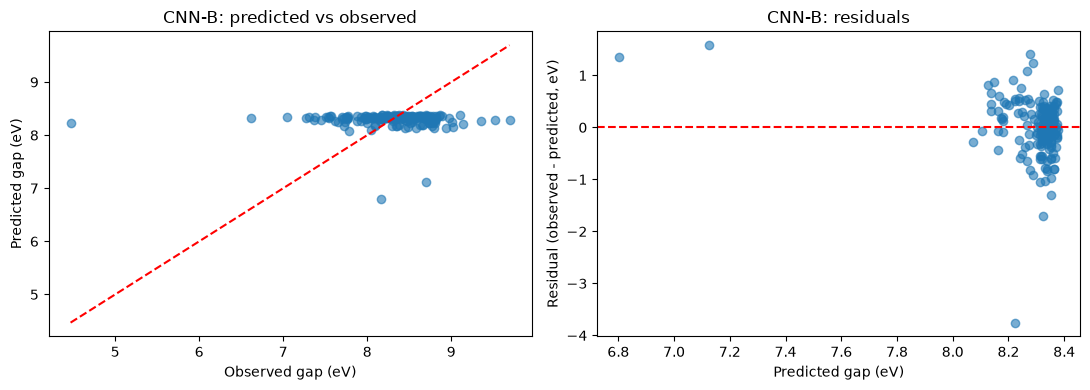

In [21]:
# Final one-time test evaluation of the locked checkpoints.
mlp_test_stats = evaluate_regression(selected_mlp, mlp_test_loader, nn.MSELoss())
cnn_test_stats = evaluate_regression(selected_cnn, cnn_test_loader, nn.MSELoss())

mlp_test_metrics = regression_metrics(mlp_test_stats["targets"], mlp_test_stats["predictions"])
cnn_test_metrics = regression_metrics(cnn_test_stats["targets"], cnn_test_stats["predictions"])

print("Selected MLP:", selected_mlp_name)
print("MLP test metrics:", {key: round(value, 4) for key, value in mlp_test_metrics.items()})
print("Selected CNN:", selected_cnn_name)
print("CNN test metrics:", {key: round(value, 4) for key, value in cnn_test_metrics.items()})

# MLP diagnostic plots.
mlp_residuals = mlp_test_stats["targets"] - mlp_test_stats["predictions"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(mlp_test_stats["targets"], mlp_test_stats["predictions"], alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Observed gap (eV)")
axes[0].set_ylabel("Predicted gap (eV)")
axes[0].set_title(f"{selected_mlp_name}: predicted vs observed")
axes[1].scatter(mlp_test_stats["predictions"], mlp_residuals, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted gap (eV)")
axes[1].set_ylabel("Residual (observed - predicted, eV)")
axes[1].set_title(f"{selected_mlp_name}: residuals")
plt.tight_layout()
plt.show()

# CNN diagnostic plots.
cnn_residuals = cnn_test_stats["targets"] - cnn_test_stats["predictions"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(cnn_test_stats["targets"], cnn_test_stats["predictions"], alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_xlabel("Observed gap (eV)")
axes[0].set_ylabel("Predicted gap (eV)")
axes[0].set_title(f"{selected_cnn_name}: predicted vs observed")
axes[1].scatter(cnn_test_stats["predictions"], cnn_residuals, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted gap (eV)")
axes[1].set_ylabel("Residual (observed - predicted, eV)")
axes[1].set_title(f"{selected_cnn_name}: residuals")
plt.tight_layout()
plt.show()

In [22]:
comparison_table = pd.DataFrame([
    {
        "model": "Section 3 baseline",
        "input_representation": "10 standardized tabular features",
        "parameter_count": 11,
        "best_validation_result": "Not applicable in Section 3",
        "test_R2": 0.2494,
        "test_MAE": 0.3011,
        "test_MSE": None,
        "test_RMSE": 0.4519,
        "training_seconds": None,
        "seed": 42,
    },
    {
        "model": selected_mlp_name,
        "input_representation": "10 standardized tabular features",
        "parameter_count": count_parameters(selected_mlp),
        "best_validation_result": selected_mlp_val_rmse,
        "test_R2": mlp_test_metrics["R2"],
        "test_MAE": mlp_test_metrics["MAE"],
        "test_MSE": mlp_test_metrics["MSE"],
        "test_RMSE": mlp_test_metrics["RMSE"],
        "training_seconds": selected_mlp_time,
        "seed": SEED,
    },
    {
        "model": selected_cnn_name,
        "input_representation": "character one-hot psmiles, (N, vocabulary, length)",
        "parameter_count": count_parameters(selected_cnn),
        "best_validation_result": selected_cnn_val_rmse,
        "test_R2": cnn_test_metrics["R2"],
        "test_MAE": cnn_test_metrics["MAE"],
        "test_MSE": cnn_test_metrics["MSE"],
        "test_RMSE": cnn_test_metrics["RMSE"],
        "training_seconds": selected_cnn_time,
        "seed": SEED,
    },
])
display(comparison_table.round(4))

,model,input_representation,parameter_count,best_validation_result,test_R2,test_MAE,test_MSE,test_RMSE,training_seconds,seed
0,Section 3 baseline,10 standardized tabular features,11,Not applicable in Section 3,0.2494,0.3011,NaN,0.4519,NaN,42
1,MLP-B,10 standardized tabular features,769,0.416207,0.1945,0.3180,0.2191,0.4681,0.2452,42
2,CNN-B,"character one-hot psmiles, (N, vocabulary, len...",2433,0.521633,-0.1018,0.3743,0.2998,0.5475,1.3406,42


### Comparison conclusions

1. **Did either neural network outperform the baseline by a practically meaningful amount?** No. The Section 3 linear baseline recorded test R2 `0.2494` and RMSE `0.4519 eV`. The selected MLP reached test R2 `0.1945` and RMSE `0.4681 eV`, and the selected CNN reached test R2 `-0.1018` and RMSE `0.5475 eV`. The CNN's negative R2 means it performed worse than predicting the test-set mean. The neural models did not beat the baseline by a practically meaningful amount.

2. **What evidence of overfitting or underfitting appears in the curves?** The MLP with the smaller learning rate was under-optimized within the epoch budget. The selected MLP and CNN both improved in training and validation loss without a clear validation rebound, so the curves alone do not show severe overfitting. However, both neural networks generalize worse on the test rows than the simpler linear baseline, and the CNN has a negative test R2. This suggests underfitting and weak generalization from the available representations rather than a model that learned the underlying relationship robustly.

3. **Because the MLP and CNN use different inputs, what can and cannot be concluded from their score difference?** The comparison is between complete pipelines on this fixed split. The MLP used standardized calculated properties, while the CNN used character sequences. The result can compare those pipelines on this dataset, but it cannot prove that one architecture is universally better.

4. **What are the two most important threats to validity?** First, the test set is small and represents a random row split from the same data population. Duplicate or near-duplicate polymer records could make performance optimistic. Second, the MLP and CNN used less training data than the Section 3 baseline because validation was carved out of the old training set; this makes the comparison imperfect. A third related risk is that `psmiles` character tokenization and truncation may lose chemical information.

5. **Which model would you carry into Section 5, and why?** Carry the Section 3 linear baseline as the stronger and simpler reference. The neural networks did not improve test performance enough to justify added complexity.

## 10. Critical review and reproducibility check

**Restart-and-run-all result:** The notebook was executed from a clean kernel and all cells completed without errors.

**One Codex suggestion accepted:** Keep the test set closed until preprocessing, vocabulary, architecture choices, and checkpoints were locked. Evidence: the final test evaluation occurs only in Section 9 after the validation-selected MLP and CNN have been frozen.

**Evidence for accepting it:** This follows the Section 3 evaluation boundary and prevents test-based tuning. The split checks also prove that test identifiers are disjoint from train and validation identifiers.

**One Codex suggestion changed or rejected:** A suggestion to add sigmoid to the regression output for a bounded prediction was rejected. Evidence: the target is a continuous energy gap in eV with values outside `[0, 1]`; `MSELoss` expects unrestricted regression outputs, and forcing a sigmoid would introduce an incorrect output-target-loss contract.

**Evidence for changing or rejecting it:** The regression contract requires `(N, 1)` floating-point outputs and targets, direct predictions, and MSE loss. No probability conversion belongs in this regression pipeline.

**Final limitation that remains after review:** The MLP and CNN were evaluated on one fixed random split and one seed, and their inputs differ from the baseline's training setup. The result is evidence for this experiment only, not a general architecture comparison.